In [11]:
import json
import numpy as np
import trimesh
import cv2
import matplotlib.pyplot as plt
import torch
import os
import logging
import torch
import hydra
import sys
from hydra import compose, initialize
from omegaconf import OmegaConf
import torch.nn.functional as F
from sklearn.decomposition import PCA
import objaverse


os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ["HYDRA_FULL_ERROR"] = "1" # Debug

# DINO
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)


In [12]:
import objaverse

UID = "04ab56ff7f5044629e424a6fcb871b76"        # Polipetto
#UID =  "026dfb57bcb5406688a7b20dfbecc6c2"    # chiave

objects = objaverse.load_objects(
    uids=[UID],
    download_processes=1
)

GLB_PATH = objects[UID]
print(f"Oggetto scaricato in: {GLB_PATH}")

Oggetto scaricato in: /home/riccardop02/.objaverse/hf-objaverse-v1/glbs/000-023/04ab56ff7f5044629e424a6fcb871b76.glb


In [13]:
os.environ["PYOPENGL_PLATFORM"] = "osmesa"  # rendering offscreen headless
import pyrender

N_VIEW = 36
IMG_SIZE = 224
CAM_DIST = 1.2
FOV_Y = np.pi / 3.0

# --- Carica e normalizza la mesh ---
scene_trimesh = trimesh.load(GLB_PATH, force="scene")
mesh_tm = scene_trimesh.dump(concatenate=True) if isinstance(scene_trimesh, trimesh.Scene) else scene_trimesh

mesh_tm.vertices -= mesh_tm.bounding_box.centroid
scale = 1.0 / np.max(mesh_tm.bounding_box.extents)
mesh_tm.vertices *= scale

mesh = pyrender.Mesh.from_trimesh(mesh_tm, smooth=False)

# --- Intrinseca (costante per tutte le viste) ---
def get_intrinsics(width, height, fov_y):
    f = height / (2 * np.tan(fov_y / 2))
    cx, cy = width / 2, height / 2
    return np.array([[f, 0, cx], [0, f, cy], [0, 0, 1]], dtype=np.float32)

K = get_intrinsics(IMG_SIZE, IMG_SIZE, FOV_Y)

# --- Look-at per orbita camera ---
def look_at(eye, target=np.array([0, 0, 0]), up=np.array([0, 1, 0])):
    forward = (target - eye)
    forward /= np.linalg.norm(forward)
    right = np.cross(forward, up)
    right /= np.linalg.norm(right)
    true_up = np.cross(right, forward)
    R_mat = np.stack([right, true_up, -forward], axis=1)
    pose = np.eye(4)
    pose[:3, :3] = R_mat
    pose[:3, 3] = eye
    return pose

renderer = pyrender.OffscreenRenderer(IMG_SIZE, IMG_SIZE)
camera = pyrender.PerspectiveCamera(yfov=FOV_Y, aspectRatio=1.0)
light = pyrender.DirectionalLight(color=np.ones(3), intensity=3.0)

# --- Dizionario principale: view_id -> {rgb, mask, K, R, ...} ---
render_data = {}

for i in range(N_VIEW):
    theta = 2 * np.pi * i / N_VIEW
    phi = np.pi / 4

    eye = CAM_DIST * np.array([
        np.cos(theta) * np.sin(phi),
        np.cos(phi),
        np.sin(theta) * np.sin(phi)
    ])

    cam_pose = look_at(eye)
    R = cam_pose[:3, :3]

    scene = pyrender.Scene(bg_color=[0.5, 0.5, 0.5, 1.0], ambient_light=[0.3, 0.3, 0.3])
    scene.add(mesh)
    scene.add(camera, pose=cam_pose)
    scene.add(light, pose=cam_pose)

    color, depth = renderer.render(scene, flags=pyrender.RenderFlags.RGBA)

    render_data[i] = {
        "rgb": color[..., :3],                       # HxWx3 uint8
        "mask": (depth > 0).astype(np.uint8) * 255,   # HxW uint8
        "K": K,
        "R_cam": R,
        "R_pose": R.T,
        "eye": eye,
        "theta": theta,
        "phi": phi,
    }

renderer.delete()

print(f"Renderizzate {N_VIEW} viste, salvate in memoria in `render_data`.")

/tmp/ipykernel_2868750/861278305.py:11: DeprecationWarning: `Scene.dump(concatenate=True)` DEPRECATED FOR REMOVAL APRIL 2025: replace with `Scene.to_geometry()`
  mesh_tm = scene_trimesh.dump(concatenate=True) if isinstance(scene_trimesh, trimesh.Scene) else scene_trimesh


Renderizzate 36 viste, salvate in memoria in `render_data`.




In [14]:
#Plotting each view and the mask
fig, axes = plt.subplots(N_VIEW, 2, figsize=(6, 3 * N_VIEW))

for i in range(N_VIEW):
    axes[i, 0].imshow(render_data[i]["rgb"])
    axes[i, 0].set_title(f"View {i} - RGB")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(render_data[i]["mask"], cmap="gray")
    axes[i, 1].set_title(f"View {i} - Mask")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


# Create The model

In [15]:
# Utilities
def load_mesh(model_path: str) -> trimesh.Trimesh:
    loaded = trimesh.load(model_path, force="mesh")

    if isinstance(loaded, trimesh.Scene):
        if len(loaded.geometry) == 0:
            raise ValueError(f"Nessuna geometria trovata in: {model_path}")
        mesh = loaded.dump(concatenate=True)
    else:
        mesh = loaded

    if not isinstance(mesh, trimesh.Trimesh):
        raise TypeError(f"Tipo mesh non supportato dopo il caricamento: {type(mesh)}")

    return mesh


def sample_pointcloud_with_color(mesh: trimesh.Trimesh, n_points: int) -> np.ndarray:
    """
    Campiona n_points sulla superficie della mesh e assegna il colore
    interpolando la UV map sulla texture.
    Ritorna (n_points, 6): xyz grezzo + rgb in [0, 255].
    """
    # Campiona punti sulla superficie; face_idx dice da quale triangolo viene ogni punto
    points, face_idx = trimesh.sample.sample_surface(mesh, n_points)

    # Coordinate baricentriche di ogni punto rispetto al suo triangolo
    triangles = mesh.triangles[face_idx]              # (n_points, 3, 3)
    bary = trimesh.triangles.points_to_barycentric(triangles, points)  # (n_points, 3)

    # UV dei 3 vertici di ogni triangolo campionato
    uv_all = mesh.visual.uv                            # (N_vertices, 2)
    face_uv = uv_all[mesh.faces[face_idx]]              # (n_points, 3, 2)

    # Interpola la UV nel punto usando le coordinate baricentriche
    point_uv = np.einsum('ij,ijk->ik', bary, face_uv)   # (n_points, 2)

    # DEF
    def get_texture_image(material):
        # Caso PBRMaterial (tipico glTF/glb)
        if hasattr(material, "baseColorTexture") and material.baseColorTexture is not None:
            return np.array(material.baseColorTexture.convert("RGB"))
        # Caso SimpleMaterial (tipico obj)
        if hasattr(material, "image") and material.image is not None:
            return np.array(material.image.convert("RGB"))
        raise AttributeError(
            f"Materiale di tipo {type(material)} non ha una texture immagine valida "
            f"(né baseColorTexture né image)."
        )


    # Campiona la texture in quelle coordinate UV
    texture_img = get_texture_image(mesh.visual.material)
    tex_h, tex_w = texture_img.shape[:2]

    u_px = np.clip((point_uv[:, 0] * (tex_w - 1)).astype(int), 0, tex_w - 1)
    v_px = np.clip(((1 - point_uv[:, 1]) * (tex_h - 1)).astype(int), 0, tex_h - 1)

    colors = texture_img[v_px, u_px].astype(np.float32)  # (n_points, 3), in [0, 255]

    return np.concatenate([points, colors], axis=-1).astype(np.float32)  # (n_points, 6)


def normalize_pointcloud(pc: np.ndarray) -> np.ndarray:
    """
    pc: (N, 6) con xyz grezzo e rgb in [0, 255].
    Ritorna (N, 6) con xyz in sfera unitaria e rgb in [-1, 1].
    """
    xyz = pc[:, :3].copy()
    rgb = pc[:, 3:].copy()

    centroid = xyz.mean(axis=0, keepdims=True)
    xyz = xyz - centroid
    scale = np.max(np.linalg.norm(xyz, axis=1))
    if scale > 0:
        xyz = xyz / scale

    rgb = (rgb / 255.0 - 0.5) / 0.5

    return np.concatenate([xyz, rgb], axis=-1).astype(np.float32)


def process_single_object(model_path: str, encoder3d, n_points: int, device: torch.device):
    """Versione single-object di process_model, per test rapido su Object 20."""
    mesh = load_mesh(model_path)
    pc = sample_pointcloud_with_color(mesh, n_points)
    pc = normalize_pointcloud(pc)

    pc_tensor = torch.from_numpy(pc).unsqueeze(0).to(device)  # (1, N, 6)

    with torch.no_grad():
        feats, centers = encoder3d.extractFeatures(pc_tensor)

    return feats.squeeze(0).cpu().numpy(), centers.squeeze(0).cpu().numpy()

def generate_rays(K: torch.Tensor, R: torch.Tensor, grid_size: int = 16, patch_size: int = 14) -> torch.Tensor:
    B = K.shape[0]
    device = K.device

    y = torch.arange(grid_size, device=device, dtype=torch.float32)
    x = torch.arange(grid_size, device=device, dtype=torch.float32)
    grid_y, grid_x = torch.meshgrid(y, x, indexing='ij')
    u = grid_x * patch_size + (patch_size / 2.0)
    v = grid_y * patch_size + (patch_size / 2.0)
    uv1 = torch.stack([u, v, torch.ones_like(u)], dim=-1).reshape(-1, 3)
    uv1 = uv1.unsqueeze(0).expand(B, -1, -1)  # (B, 256, 3)

    K_inv = torch.linalg.inv(K)
    d_c = torch.bmm(uv1, K_inv.transpose(1, 2))

    R_inv = R.transpose(1, 2)
    d_o = torch.bmm(d_c, R_inv.transpose(1, 2))  # Object space rays

    return F.normalize(d_o, p=2, dim=-1)

def masked_l1_per_sample(pred_tensor, targ_tensor, mask_tensor):
    """Restituisce la L1 mascherata per ogni elemento del batch: shape (B,)"""
    err = F.l1_loss(pred_tensor, targ_tensor, reduction='none').mean(dim=-1)  # (B, N)
    valid = mask_tensor.float()
    return (err * valid).sum(dim=1) / valid.sum(dim=1).clamp(min=1.0)


In [16]:
# Instatiate the model

sys.path.insert(0, "/home/riccardop02/JEPA")

logging.basicConfig(level=logging.INFO)
log = logging.getLogger(__name__)

# --- Config ---
with initialize(version_base=None, config_path="../../configs"):
    cfg = compose(config_name="config")

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Only for the UNI3D
cfg.encoder3d['ckpt_path'] = "/home/riccardop02/JEPA/weights/model.pt"

# --- Istanzia i modelli ---
encoder2d = hydra.utils.instantiate(cfg.encoder2d)
encoder3d = hydra.utils.instantiate(cfg.encoder3d)
encoder2d.to(device)
encoder3d.to(device)
log.info("Dino Initialized...")
log.info(f"Encoder2d: {type(encoder2d)}, output_dim: {encoder2d.output_dim}, "
          f"layers: {encoder2d.layers}, token: {encoder2d.token}")
log.info(f"Encoder3d: {type(encoder3d)}, output_dim: {encoder3d.output_dim}")

predictor = hydra.utils.instantiate(
    cfg.Predictor,
    context_dim=encoder3d.output_dim[0][-1],
    output_dim=encoder2d.output_dim[-1]
)
predictor.to(device)

# predictor appena inizializzato (pesi random), per confronto/test strutturale
predictor_init = hydra.utils.instantiate(
    cfg.Predictor, context_dim=encoder3d.output_dim[0][-1], output_dim=encoder2d.output_dim[-1]
).to(device)
predictor_init.eval()

# --- Carica checkpoint ---
PATH_CHECK = '/experiments/riccardop02/outputs/2026-09-01/14-16-14/checkpoints/best.pt' 
checkpoint = torch.load(PATH_CHECK, map_location=device)

encoder2d.load_state_dict(checkpoint["models"]['encoder2d'])
predictor.load_state_dict(checkpoint["models"]['predictor'])
encoder3d.load_state_dict(checkpoint["models"]['encoder3d'])

encoder2d.eval()
predictor.eval()
encoder3d.eval()
log.info(f"Checkpoint loaded from {PATH_CHECK}")




INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/resolve/main/preprocessor_config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/facebook/dinov2-base/f9e44c814b77203eaa57a6bdbbd535f21ede1415/preprocessor_config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/resolve/main/preprocessor_config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/facebook/dinov2-base/f9e44c814b77203eaa57a6bdbbd535f21ede1415/preprocessor_config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

INFO:root:Uni3D constructed, loading Uni3D weights from /home/riccardop02/JEPA/weights/model.pt ...
INFO:__main__:Dino Initialized...
INFO:__main__:Encoder2d: <class 'src.models.encoder2d.DINOv2.DINOv2'>, output_dim: torch.Size([256, 768]), layers: [-1], token: PatchToken
INFO:__main__:Encoder3d: <class 'src.models.encoder3d.Uni3D.Uni3DEncoder'>, output_dim: ((1, 512, 768), (1, 512, 3))
INFO:root:RayCrossAttnPredictor initialized (depth=6, FourierBands=6)
INFO:root:RayCrossAttnPredictor initialized (depth=6, FourierBands=6)
/tmp/ipykernel_2868750/4200245983.py:42: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`

In [17]:
# compute feature of the object
feats3d, centers= process_single_object(GLB_PATH, encoder3d, n_points=8192, device=device)

log.info(f"3D features: {feats3d.shape}, centers: {centers.shape}")


INFO:__main__:3D features: (512, 768), centers: (512, 3)


In [18]:
from PIL import Image as PILImage

def pixel_mask_to_token_mask(mask, grid_size=16):
    mask_pil = PILImage.fromarray((mask.astype(np.uint8)) * 255 if mask.max() <= 1 else mask.astype(np.uint8))
    mask_grid = mask_pil.resize((grid_size, grid_size), PILImage.BOX)
    return np.array(mask_grid, dtype=np.float32) / 255.0  # valori continui [0,1]

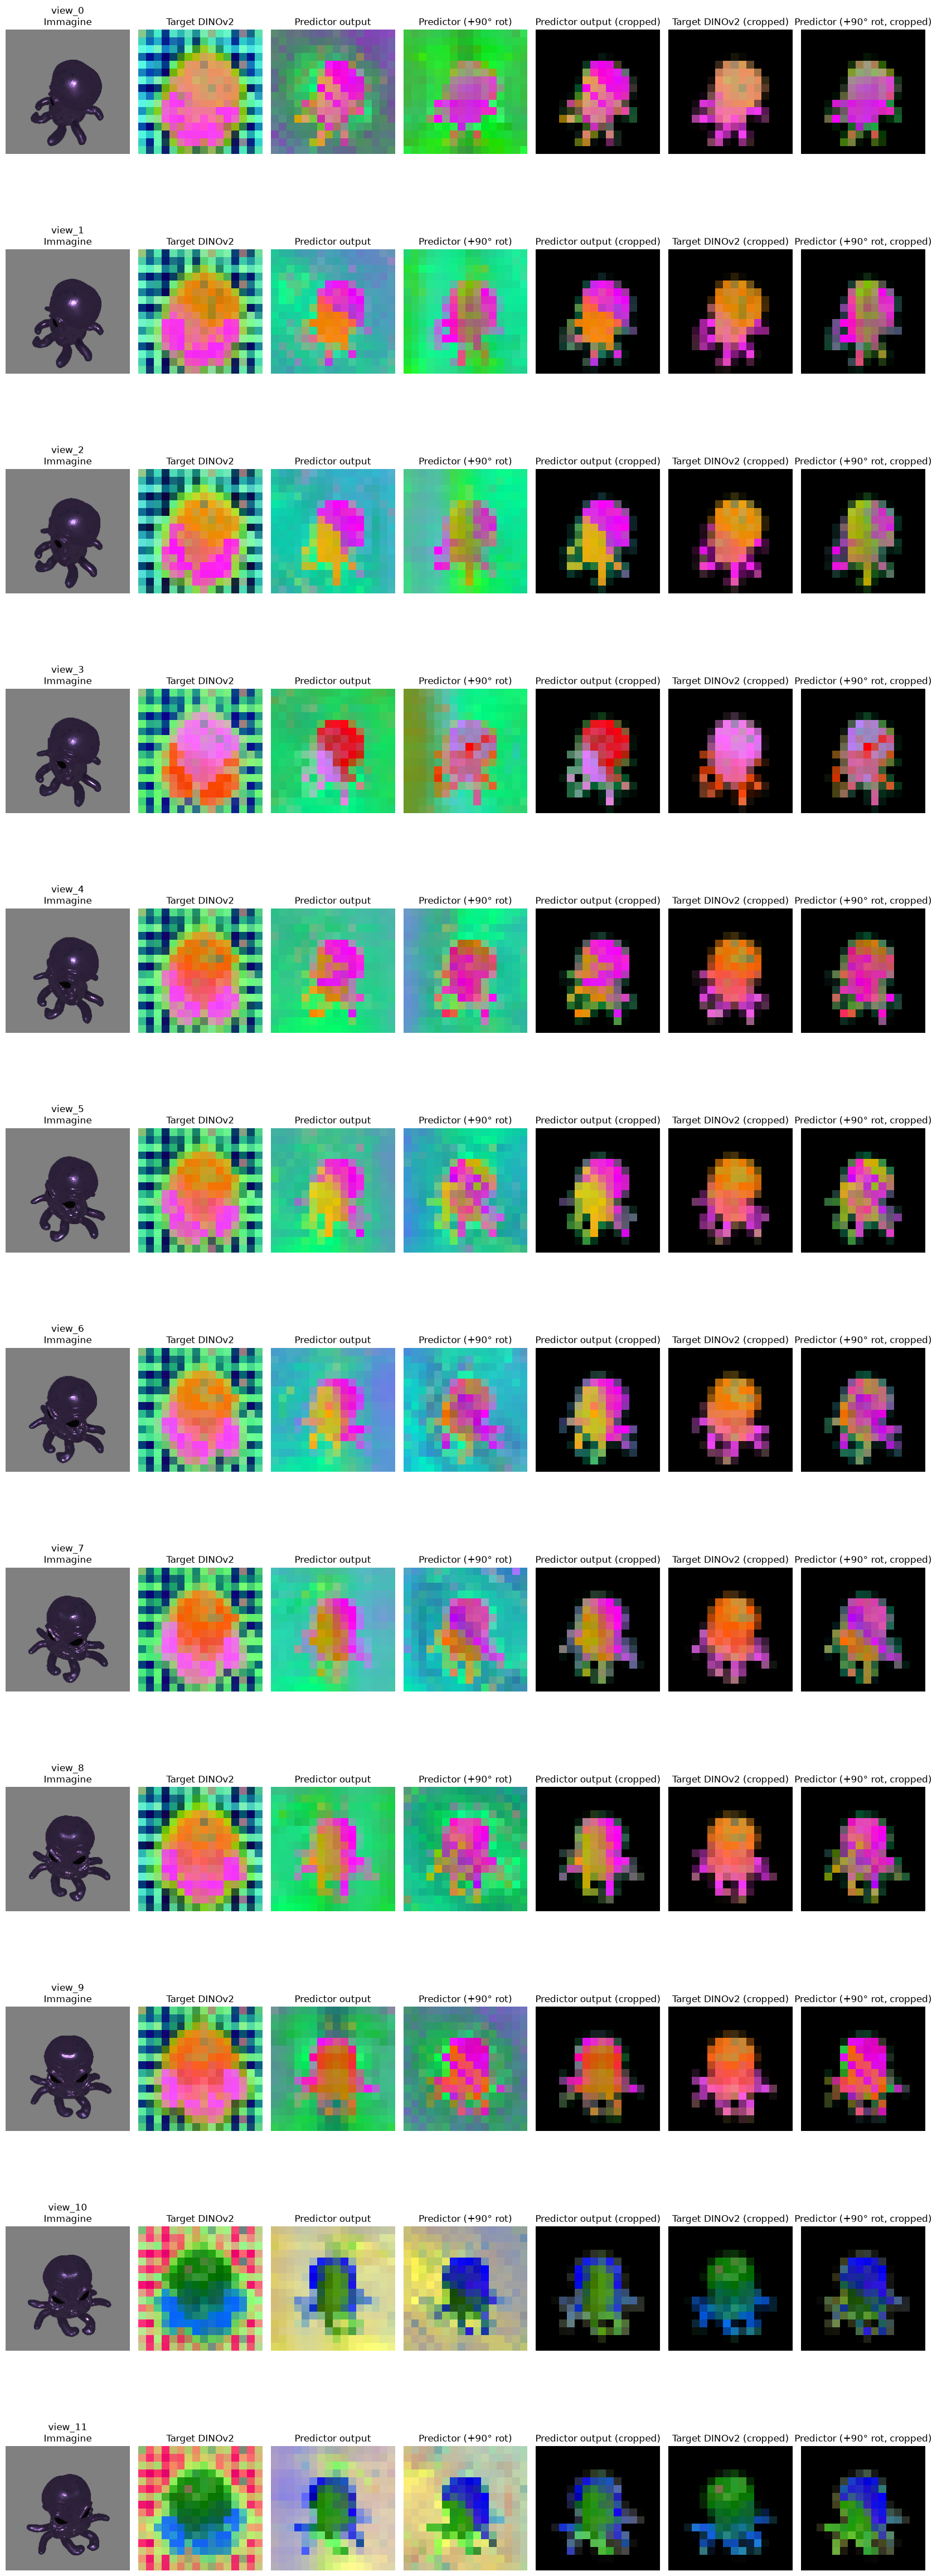

In [19]:
from sklearn.decomposition import PCA

N_OBJECTS = min(12, len(render_data))
GRID_SIZE = 16
WRONG_ROT_DEG = 90.0  # gradi di rotazione errata da aggiungere

MEAN_t = torch.tensor(MEAN, dtype=torch.float32, device=device).view(1, 3, 1, 1)
STD_t = torch.tensor(STD, dtype=torch.float32, device=device).view(1, 3, 1, 1)

context_t = torch.from_numpy(feats3d).unsqueeze(0).to(device)
centers_t = torch.from_numpy(centers).unsqueeze(0).to(device)

def to_rgb_map_local(pca_tokens, grid_size=GRID_SIZE):
    """Normalizzazione min/max LOCALE, calcolata solo sui token passati (come nello script di validation)."""
    vmin = pca_tokens.min(axis=0, keepdims=True)
    vmax = pca_tokens.max(axis=0, keepdims=True)
    norm = (pca_tokens - vmin) / (vmax - vmin + 1e-8)
    norm = np.clip(norm, 0, 1)
    return norm.reshape(grid_size, grid_size, 3)

def rotation_matrix(axis, deg, device):
    """Matrice di rotazione 3x3 attorno a un asse ('x', 'y' o 'z')."""
    rad = np.deg2rad(deg)
    c, s = np.cos(rad), np.sin(rad)
    if axis == 'x':
        R = np.array([[1, 0, 0],
                      [0, c, -s],
                      [0, s,  c]], dtype=np.float32)
    elif axis == 'y':
        R = np.array([[ c, 0, s],
                      [ 0, 1, 0],
                      [-s, 0, c]], dtype=np.float32)
    elif axis == 'z':
        R = np.array([[c, -s, 0],
                      [s,  c, 0],
                      [0,  0, 1]], dtype=np.float32)
    else:
        raise ValueError("axis deve essere 'x', 'y' o 'z'")
    return torch.from_numpy(R).to(device)

R_offset = rotation_matrix('y', WRONG_ROT_DEG, device)  # <-- cambia asse se serve

view_ids = list(render_data.keys())[:N_OBJECTS]

fig, axes = plt.subplots(N_OBJECTS, 7, figsize=(16.8, 4 * N_OBJECTS))
if N_OBJECTS == 1:
    axes = axes[None, :]

for i, vid in enumerate(view_ids):
    view = render_data[vid]

    img_np = view["rgb"].astype(np.float32) / 255.0
    img_t = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).to(device)
    img_t = (img_t - MEAN_t) / STD_t

    K_t = torch.from_numpy(view["K"]).unsqueeze(0).to(device).float()
    rot_t = torch.from_numpy(view["R_cam"]).unsqueeze(0).to(device).float()

    # rotazione "sbagliata" = rotazione originale + offset di WRONG_ROT_DEG
    rot_wrong_t = torch.matmul(R_offset.unsqueeze(0).float(), rot_t)

    token_mask_np = pixel_mask_to_token_mask(view["mask"], grid_size=GRID_SIZE)
    mask_t = torch.from_numpy(token_mask_np.reshape(-1)).float().unsqueeze(0).to(device)
    
    ray_dirs = generate_rays(K_t, rot_t)
    ray_dirs_wrong = generate_rays(K_t, rot_wrong_t)

    with torch.no_grad():
        target = encoder2d(img_t)
        pred = predictor(
            ray_queries=ray_dirs,
            context_features=context_t,
            context_centers=centers_t,
            mask=mask_t
        )
        pred_wrong = predictor(
            ray_queries=ray_dirs_wrong,
            context_features=context_t,
            context_centers=centers_t,
            mask=mask_t
        )

    target_np = target.squeeze(0).cpu().numpy()          # (256, 768)
    pred_np = pred.squeeze(0).cpu().numpy()               # (256, 768)
    pred_wrong_np = pred_wrong.squeeze(0).cpu().numpy()    # (256, 768)

    # --- PCA fittata SOLO sul target di QUESTA vista ---
    pca = PCA(n_components=3)
    target_pca = pca.fit_transform(target_np)
    pred_pca = pca.transform(pred_np)
    pred_wrong_pca = pca.transform(pred_wrong_np)  # stessa PCA del target, come richiesto

    # --- Normalizzazione min/max LOCALE ---
    target_map = to_rgb_map_local(target_pca)
    pred_map = to_rgb_map_local(pred_pca)
    pred_wrong_map = to_rgb_map_local(pred_wrong_pca)

    img_denorm = (img_t * STD_t + MEAN_t).clamp(0, 1)
    bg_img = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

    axes[i, 0].imshow(bg_img)
    axes[i, 0].set_title(f"view_{vid}\nImmagine")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(target_map)
    axes[i, 1].set_title("Target DINOv2")
    axes[i, 1].axis('off')

    axes[i, 2].imshow(pred_map)
    axes[i, 2].set_title("Predictor output")
    axes[i, 2].axis('off')

    axes[i, 3].imshow(pred_wrong_map)
    axes[i, 3].set_title(f"Predictor (+{WRONG_ROT_DEG:.0f}° rot)")
    axes[i, 3].axis('off')

    axes[i, 4].imshow(pred_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1))
    axes[i, 4].set_title("Predictor output (cropped)")
    axes[i, 4].axis('off')

    axes[i, 5].imshow(target_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1))
    axes[i, 5].set_title("Target DINOv2 (cropped)")
    axes[i, 5].axis('off')


    axes[i, 6].imshow(pred_wrong_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1))
    axes[i, 6].set_title(f"Predictor (+{WRONG_ROT_DEG:.0f}° rot, cropped)")
    axes[i, 6].axis('off')

plt.tight_layout()
plt.show();

In [20]:
print(plt.get_backend())

module://matplotlib_inline.backend_inline
